# Chapter 15: Grids and Matrices

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 15.1 Small Multiples with col= and row=

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

In [2]:
orders = pd.read_csv('orders.csv')
orders.head(4)

,channel,category,region,items,order_value,delivery_days
0,In store,Storage,Pacific,2,88,4
1,In store,Accessories,Pacific,3,56,3
2,Online,Displays,Pacific,1,176,2
3,In store,Audio,Pacific,3,169,1


### `col=`

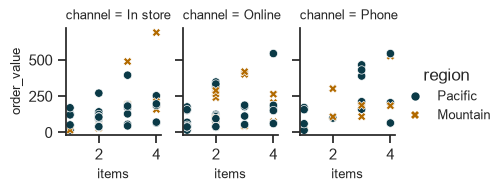

In [3]:
g = sns.relplot(data=orders, kind='scatter', x='items',
                y='order_value', col='channel',
                hue='region', style='region',
                height=2, aspect=0.7)
plt.show()

### `col_wrap=`

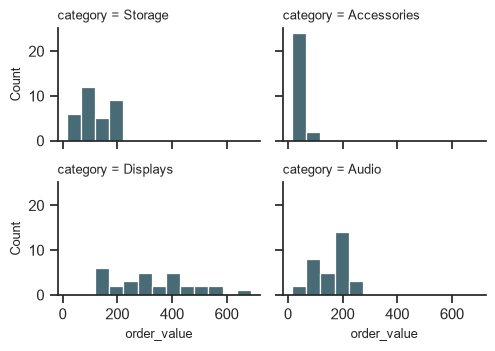

In [4]:
g = sns.displot(data=orders, x='order_value', col='category',
                col_wrap=2, binwidth=50, height=1.8, aspect=1.4)
plt.show()

### `row=`

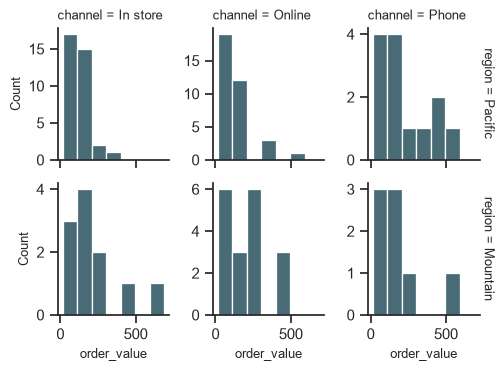

In [5]:
g = sns.displot(data=orders, x='order_value', row='region',
                col='channel', binwidth=100, height=1.9,
                aspect=0.9,
                facet_kws={'sharey': False, 'margin_titles': True})
plt.show()

## 15.2 Finishing a Grid

### `g.set_axis_labels()` and `g.set_titles()`

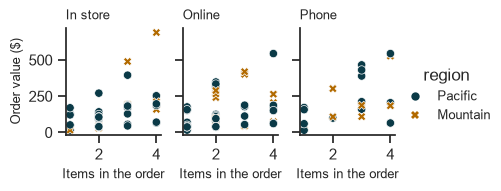

In [6]:
g = sns.relplot(data=orders, kind='scatter', x='items',
                y='order_value', col='channel',
                hue='region', style='region',
                height=2, aspect=0.7)
g.set_axis_labels('Items in the order', 'Order value ($)')
g.set_titles('{col_name}')
plt.show()

### `sns.move_legend()`

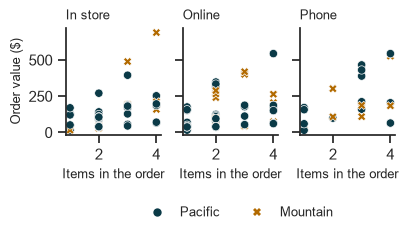

In [7]:
g = sns.relplot(data=orders, kind='scatter', x='items',
                y='order_value', col='channel',
                hue='region', style='region',
                height=2, aspect=0.7)
g.set_axis_labels('Items in the order', 'Order value ($)')
g.set_titles('{col_name}')
sns.move_legend(g, 'upper center', bbox_to_anchor=(0.5, 0),
                ncol=2, title=None, frameon=False)
plt.show()

## 15.3 Comparing Every Pair with pairplot()

In [8]:
daily = pd.read_csv('daily_shop.csv')
daily.head(3)

,day,ad_spend,visitors,orders,revenue,delivery,returns,rating
0,Weekday,351,780,20,1580,3,0,4.1
1,Weekday,209,650,16,830,4,2,4.1
2,Weekday,340,820,20,1790,2,3,4.2


### `sns.pairplot()`

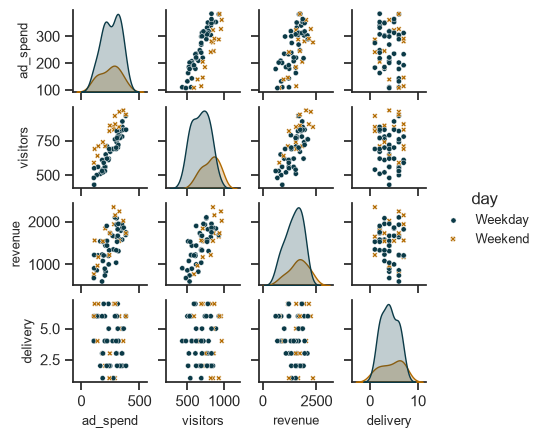

In [9]:
g = sns.pairplot(data=daily, hue='day',
                 vars=['ad_spend', 'visitors', 'revenue',
                       'delivery'],
                 markers=['o', 'X'], height=1.1,
                 plot_kws={'s': 14})
plt.show()

### `corner=True`

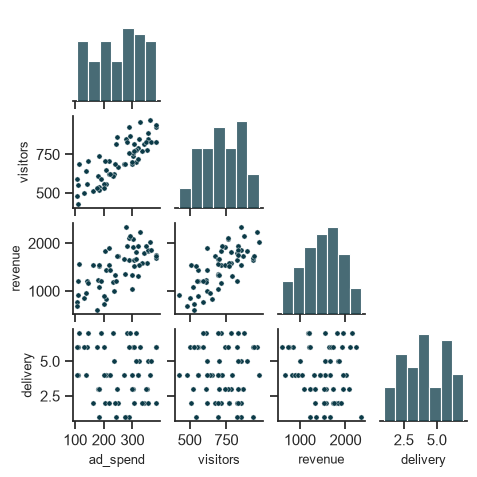

In [10]:
g = sns.pairplot(data=daily, corner=True,
                 vars=['ad_spend', 'visitors', 'revenue',
                       'delivery'],
                 height=1.2, plot_kws={'s': 14})
plt.show()

## 15.4 Heatmaps

### `sns.heatmap()`

In [11]:
counts = orders.pivot_table(index='channel', columns='category',
                            values='items', aggfunc='count')
counts

category,Accessories,Audio,Displays,Storage
channel,,,,
In store,11,15,7,13
Online,12,12,15,14
Phone,3,5,8,5


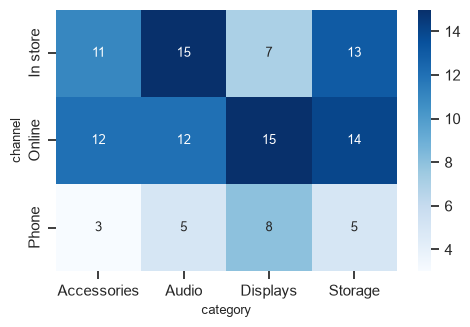

In [12]:
ax = sns.heatmap(counts, annot=True, fmt='d', cmap='Blues')
plt.show()

### A correlation heatmap

In [13]:
corr = daily.corr(numeric_only=True)
corr.round(2)

,ad_spend,visitors,orders,revenue,delivery,returns,rating
ad_spend,1.00,0.82,0.72,0.66,-0.14,-0.19,0.13
visitors,0.82,1.00,0.87,0.73,-0.05,-0.12,0.02
orders,0.72,0.87,1.00,0.75,-0.05,-0.11,0.04
revenue,0.66,0.73,0.75,1.00,-0.14,-0.10,0.08
delivery,-0.14,-0.05,-0.05,-0.14,1.00,0.72,-0.82
returns,-0.19,-0.12,-0.11,-0.10,0.72,1.00,-0.59
rating,0.13,0.02,0.04,0.08,-0.82,-0.59,1.00


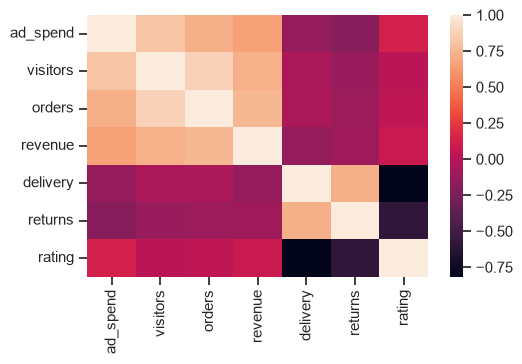

In [14]:
ax = sns.heatmap(corr)
plt.show()

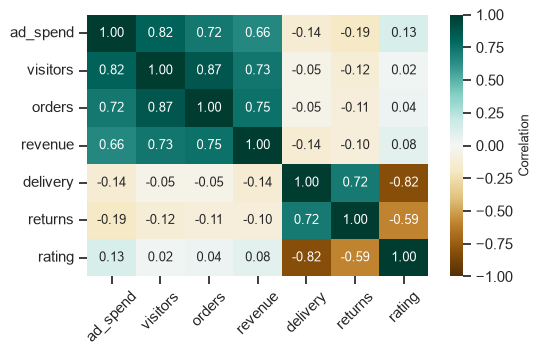

In [15]:
ax = sns.heatmap(corr, annot=True, fmt='.2f', cmap='BrBG',
                 center=0, vmin=-1, vmax=1,
                 cbar_kws={'label': 'Correlation'})
ax.tick_params(axis='x', rotation=45)
ax.figure.savefig('correlations.png', dpi=200, bbox_inches='tight')
plt.show()

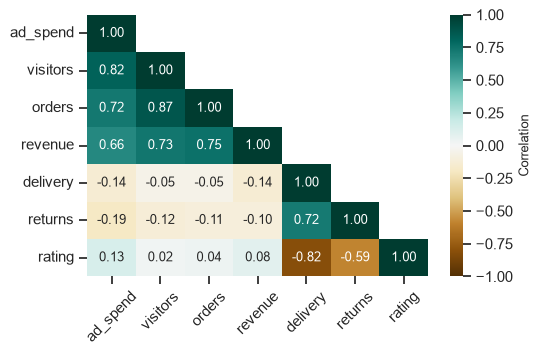

In [16]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
ax = sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
                 cmap='BrBG', center=0, vmin=-1, vmax=1,
                 cbar_kws={'label': 'Correlation'})
ax.tick_params(axis='x', rotation=45)
plt.show()

## 15.5 Finishing with matplotlib

In [17]:
g = sns.catplot(data=orders, kind='bar', x='region',
                y='order_value', col='category', col_wrap=2,
                errorbar=None, height=1.8, aspect=1.4)
plt.close(g.figure)
g.axes.shape

(4,)

### Finishing a grid

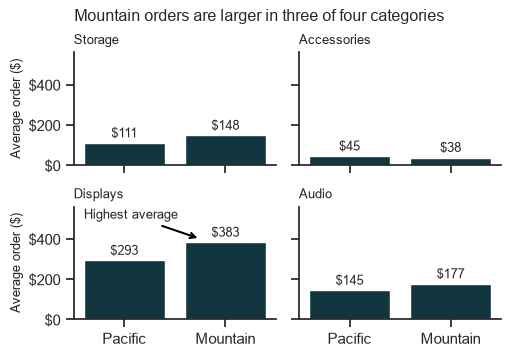

In [18]:
g = sns.catplot(data=orders, kind='bar', x='region',
                y='order_value', col='category', col_wrap=2,
                errorbar=None, height=1.8, aspect=1.4)
g.set_axis_labels('', 'Average order ($)')
g.set_titles('{col_name}')
for ax in g.axes.flat:
    ax.bar_label(ax.containers[0], fmt='${:,.0f}', padding=2)
    ax.yaxis.set_major_formatter('${x:,.0f}')
    ax.set_ylim(0, 560)
g.axes_dict['Displays'].annotate(
    'Highest average', xy=(0.75, 400), xytext=(-0.4, 500),
    arrowprops={'arrowstyle': '->', 'lw': 1.5, 'color': 'black'})
g.figure.suptitle('Mountain orders are larger in three of '
                  'four categories', y=1.03)
g.savefig('orders_by_category.png', dpi=200)
plt.show()